# Credit Risk Prediction

Predict whether a borrower will have a serious delinquency within the next 2 years, using their credit history and income data.

- **Dataset:** [Kaggle – Credit Risk Benchmark Dataset](https://www.kaggle.com/datasets/adilshamim8/credit-risk-benchmark-dataset)
- **Target:** `dlq_2yrs` (1 = serious delinquency, 0 = none)
- **Models:** Logistic Regression and XGBoost
- **Main metric:** PR-AUC (average precision), supported by recall, ROC-AUC, Gini, F1 and KS
- **Final model:** XGBoost, with a test PR-AUC of 0.859, ROC-AUC of 0.861 and KS of 0.566

## Data dictionary

| Column | Description |
|---|---|
| `rev_util` | Ratio of revolving credit utilization (balance/credit limit) |
| `age` | Age of the borrower |
| `late_30_59` | Number of times 30-59 days past due (worse than current) |
| `debt_ratio` | Debt to income (or assets) ratio |
| `monthly_inc` | Monthly income of the borrower |
| `open_credit` | Number of open credit lines and loans |
| `late_90` | Number of times 90 days or more late on a payment |
| `real_estate` | Number of real estate loans or credit lines |
| `late_60_89` | Number of times 60-89 days past due (worse than current) |
| `dependents` | Number of dependents |
| `dlq_2yrs` | Target: whether a serious delinquency occurred in the next 2 years (0 = No, 1 = Yes) |

# 1. Setup

Install the packages, import the libraries, and set the random seed and data path.

In [1]:
%pip install -U pip
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
import joblib
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, recall_score, average_precision_score, ConfusionMatrixDisplay,  
                             roc_auc_score, f1_score, roc_curve, precision_recall_curve, classification_report)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import shap
from sklearn.model_selection import train_test_split

C:\Users\User\anaconda3\envs\Data-Science-Projects\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
RANDOM_SEED = 42
PROJECT_FOLDER = Path.cwd()
DATA_FILE = PROJECT_FOLDER / "data" / "Credit Risk Benchmark Dataset.csv"

# 2. Load the data

Load the CSV, then check its shape, missing values, duplicates and data types.

In [4]:
raw_data = pd.read_csv(DATA_FILE)
credit_risk_data = raw_data.copy()
credit_risk_data.head()

,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,dlq_2yrs
0,0.006999,38.0,0.0,0.302150,5440.0,4.0,0.0,1.0,0.0,3.0,0
1,0.704592,63.0,0.0,0.471441,8000.0,9.0,0.0,1.0,0.0,0.0,0
2,0.063113,57.0,0.0,0.068586,5000.0,17.0,0.0,0.0,0.0,0.0,0
3,0.368397,68.0,0.0,0.296273,6250.0,16.0,0.0,2.0,0.0,0.0,0
4,1.000000,34.0,1.0,0.000000,3500.0,0.0,0.0,0.0,0.0,1.0,0


In [5]:
print("Shape:", credit_risk_data.shape)
print("Missing values per column:", credit_risk_data.isna().sum().sum())
print("Duplicate rows:", credit_risk_data.duplicated().sum())
print(credit_risk_data.dtypes)

Shape: (16714, 11)
Missing values per column: 0
Duplicate rows: 2
rev_util       float64
age            float64
late_30_59     float64
debt_ratio     float64
monthly_inc    float64
open_credit    float64
late_90        float64
real_estate    float64
late_60_89     float64
dependents     float64
dlq_2yrs         int64
dtype: object


In [6]:
credit_risk_data[credit_risk_data.duplicated()]

,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,dlq_2yrs
11054,1.0,22.0,98.0,0.0,0.0,0.0,98.0,0.0,98.0,0.0,1
12257,1.0,55.0,0.0,0.0,1000.0,0.0,1.0,0.0,0.0,0.0,1


The dataset has 16,714 rows, 10 features and no missing values. The 2 duplicate rows are kept, because there is no borrower ID to confirm they are the same person.

# 3. EDA

Check the class balance, feature distributions, outliers, placeholder values and correlations.

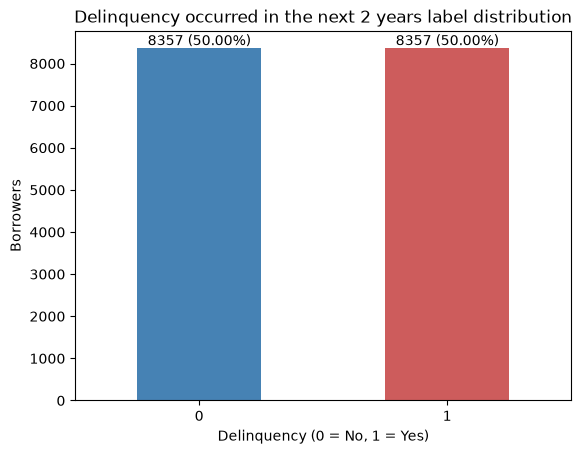

In [7]:
label_counts = credit_risk_data["dlq_2yrs"].value_counts().sort_index()
axis = label_counts.plot(kind="bar", color=["steelblue", "indianred"], rot=0)
axis.bar_label(axis.containers[0],
               labels=[f"{count} ({count / label_counts.sum():.2%})" for count in label_counts])
axis.set(title="Delinquency occurred in the next 2 years label distribution", xlabel="Delinquency (0 = No, 1 = Yes)", ylabel="Borrowers")
plt.show()

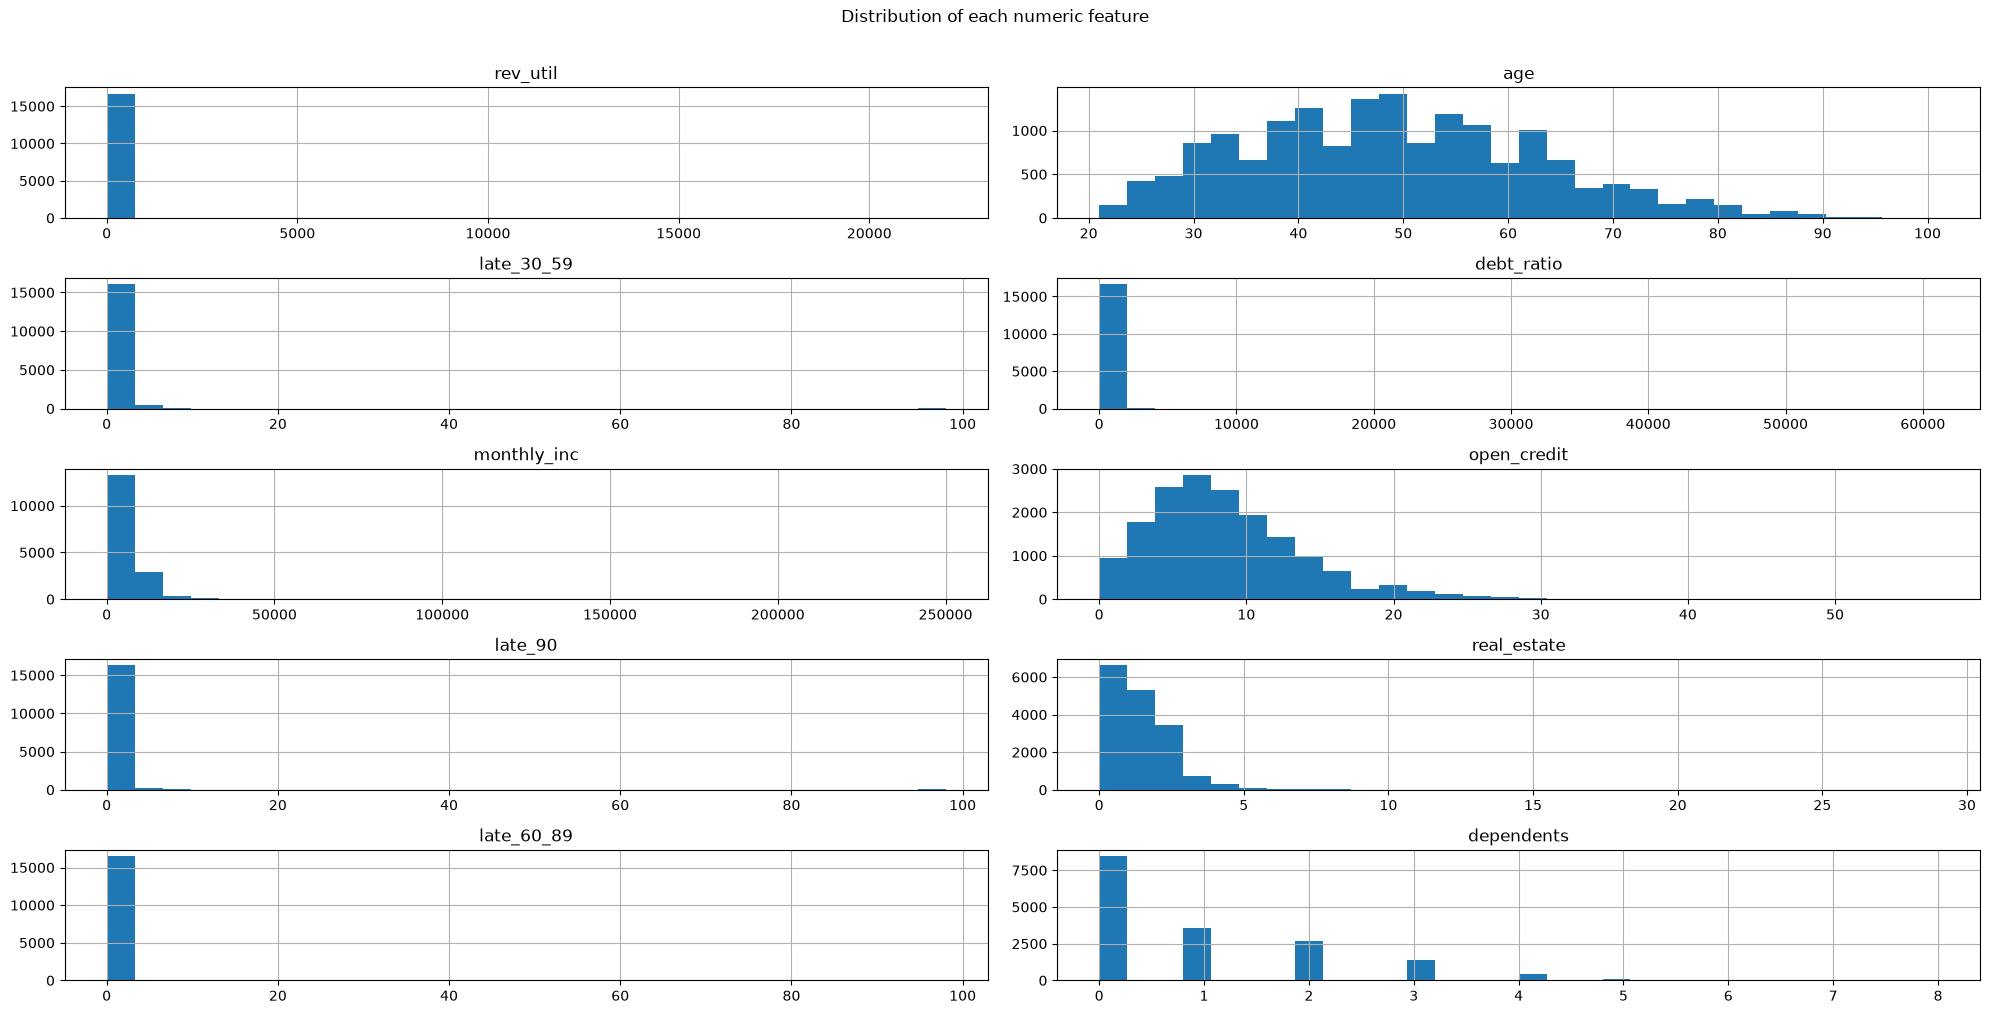

In [8]:
numeric_columns = (credit_risk_data.select_dtypes("number").columns
                   .drop(["dlq_2yrs"]))
credit_risk_data[numeric_columns].hist(bins=30, figsize=(20, 10), layout=(5, 2))
plt.suptitle("Distribution of each numeric feature", y=1.01)
plt.tight_layout()
plt.show()

## Outliers by class

Each boxplot compares a feature across the two classes, with delinquent borrowers overlaid in red.

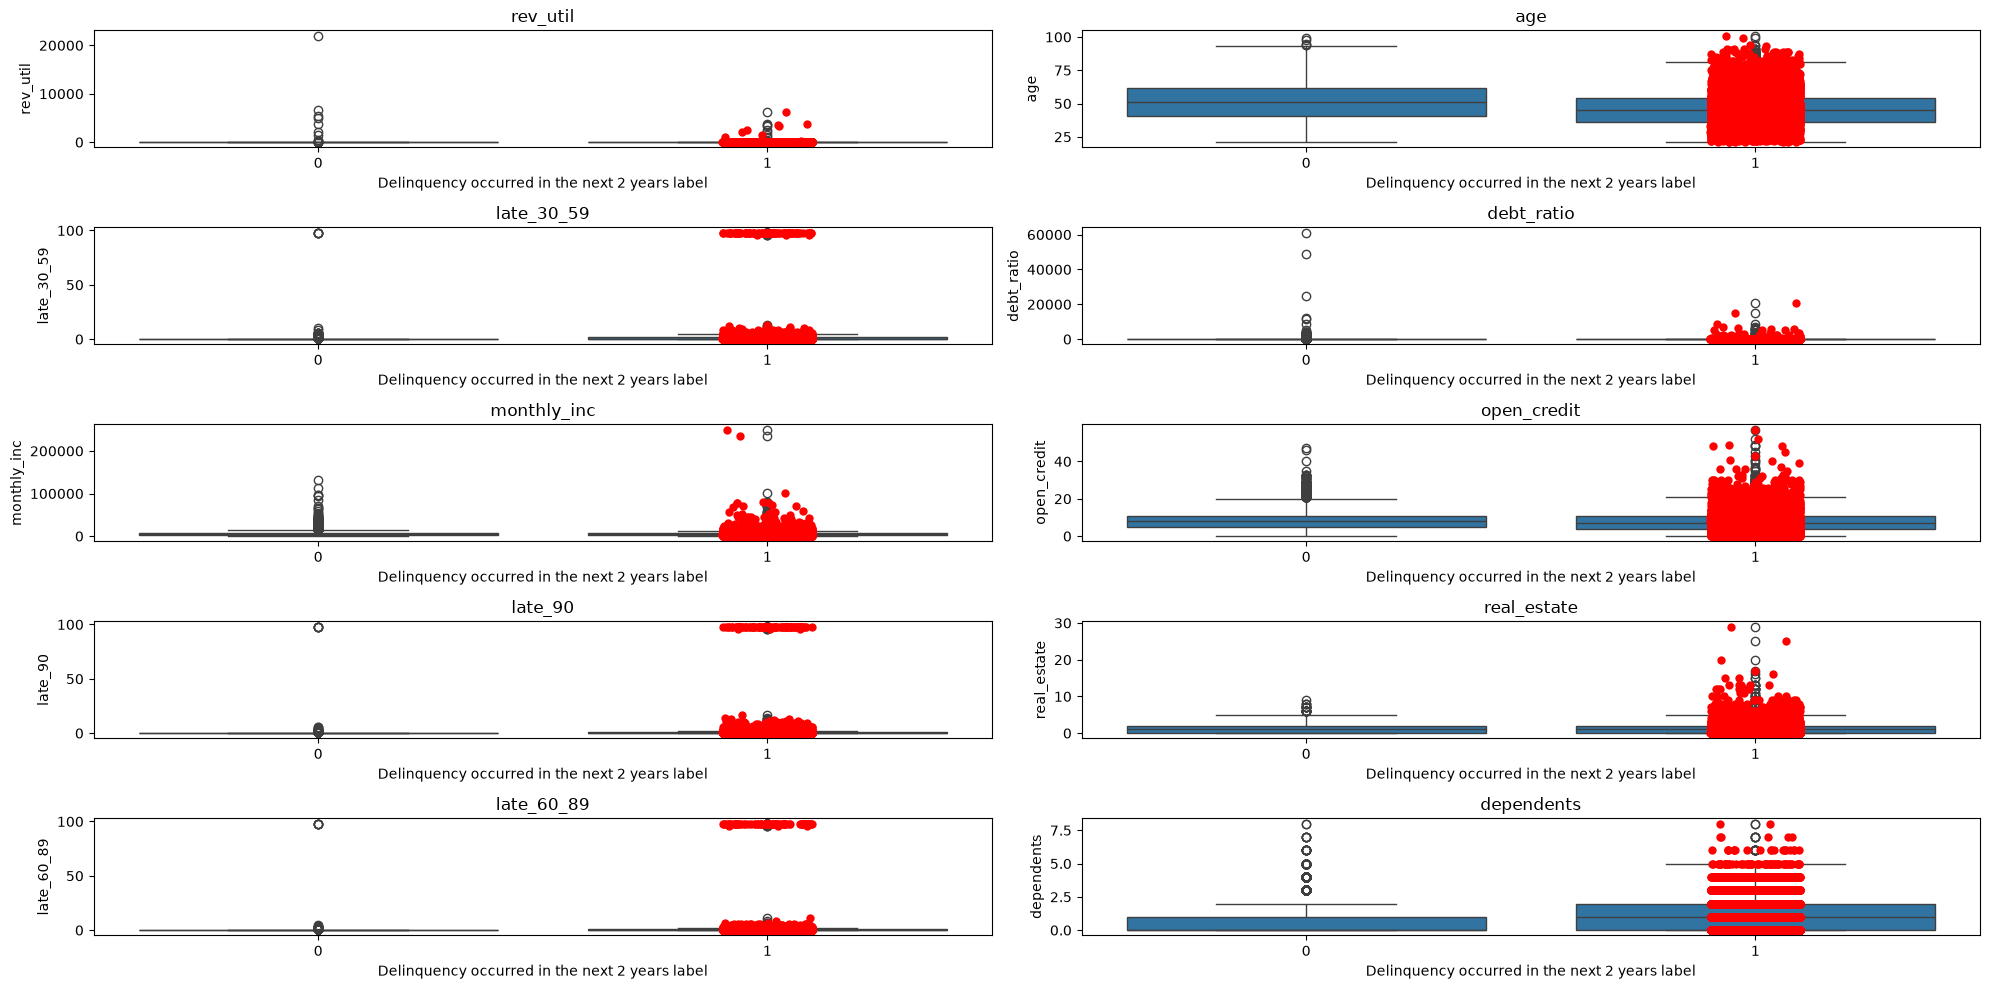

In [9]:
figure, axes = plt.subplots(5, 2, figsize=(20, 10))
for axis, column in zip(axes.flat, numeric_columns):
    sns.boxplot(data=credit_risk_data, x=credit_risk_data["dlq_2yrs"], y=column, ax=axis)
    sns.stripplot(data=credit_risk_data[credit_risk_data["dlq_2yrs"] == 1], x=credit_risk_data["dlq_2yrs"], y=column,
                  ax=axis, color="red", size=6)
    axis.set(title=column, xlabel="Delinquency occurred in the next 2 years label")
plt.tight_layout()
plt.show()

## Placeholder check

Some late-payment counts reach 96–98, far above the other values. This cell checks how many borrowers have these values and how often those borrowers are delinquent.

In [10]:
late_columns = ["late_30_59", "late_60_89", "late_90"]
print(credit_risk_data[late_columns].stack().value_counts().sort_index().tail(8))

placeholder_rows = credit_risk_data[late_columns].ge(96).any(axis=1)
print("Placeholder rows:", placeholder_rows.sum())
print("Delinquency rate in those rows:", credit_risk_data.loc[placeholder_rows, "dlq_2yrs"].mean())
print(credit_risk_data.loc[~placeholder_rows, late_columns + ["dlq_2yrs"]].corr().round(2))

10.0      8
11.0      5
12.0      2
13.0      3
14.0      1
17.0      1
96.0      9
98.0    258
Name: count, dtype: int64
Placeholder rows: 89
Delinquency rate in those rows: 0.9438202247191011
            late_30_59  late_60_89  late_90  dlq_2yrs
late_30_59        1.00        0.33     0.22      0.35
late_60_89        0.33        1.00     0.32      0.28
late_90           0.22        0.32     1.00      0.31
dlq_2yrs          0.35        0.28     0.31      1.00


## Correlation

Spearman correlation uses ranks, so extreme values have much less effect than they do on Pearson correlation.

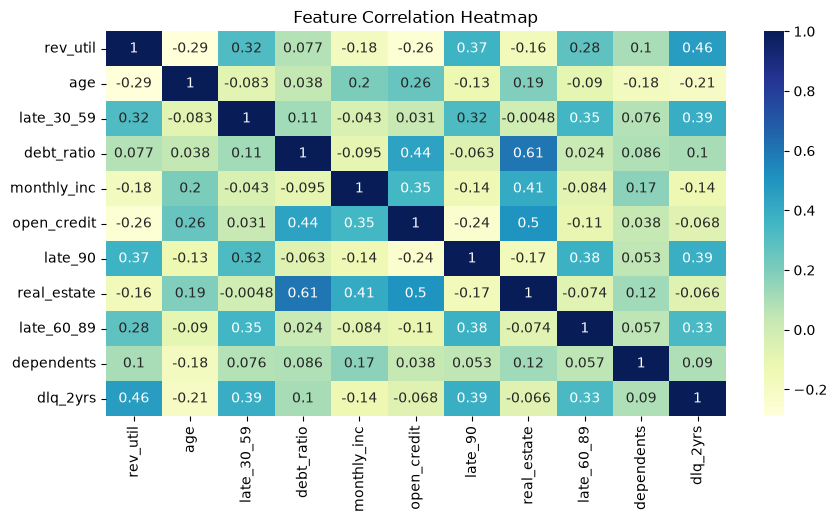

In [11]:
# Correlation Heatmap

plt.figure(figsize=(10,5))
sns.heatmap(credit_risk_data.corr(method="spearman"),cmap="YlGnBu",annot=True)
plt.title("Feature Correlation Heatmap")
plt.show()

## Findings

- **Class balance:** `dlq_2yrs` is balanced, with 8,357 borrowers (50%) in each class. Real portfolios have far fewer delinquent borrowers, so the results apply to this balanced sample.
- **Skew:** most features are strongly right-skewed, so they are log-transformed and scaled before modeling.
- **Outliers:** every feature has outliers, and `rev_util` and `debt_ratio` reach about 22,000 and 60,000. They are kept because they may be linked to delinquency.
- **Placeholder values:** 89 borrowers (0.5%) have 96 or 98 in all three late-payment columns, while the next highest value is 17. These look like codes rather than real counts, but they carry real signal: 94.4% of these borrowers are delinquent, against 50% overall. They are kept.
- **Correlation:** Spearman correlation is used because extreme values distort Pearson. `rev_util` has the strongest correlation with the target (0.46), followed by `late_30_59` and `late_90` (0.39 each) and `late_60_89` (0.33).
- **Feature selection:** all features are kept, because Spearman only measures monotonic relationships. For example, `open_credit` has a low correlation (−0.07) but still affects the model in SHAP.

# 4. Data Preprocessing

Apply `log1p` to reduce skew, then standard scaling. Both steps sit inside a scikit-learn `Pipeline`, so they are fitted on training folds only and test data cannot leak into them. Logistic Regression and XGBoost use the same preprocessing.

In [12]:
feature_data = credit_risk_data.drop(columns=["dlq_2yrs"])
target = credit_risk_data["dlq_2yrs"]

numeric_feature_names = feature_data.select_dtypes("number").columns.tolist()

# Log transformation
log_transformer = FunctionTransformer(np.log1p, validate=True)

# Pipeline for log transform + standard scaling
log_then_scale_pipeline = Pipeline([
    ('log', log_transformer),
    ('scale', StandardScaler())
])

preprocessor = ColumnTransformer([
    ("numeric", log_then_scale_pipeline, numeric_feature_names)
])

# 5. Modeling and Evaluation

The data is split 75/25 with stratification, giving 12,535 training rows and 4,179 test rows. Each model is tuned with `RandomizedSearchCV`, using 10-fold cross-validation scored on average precision.

In [13]:
X, y = feature_data, target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_SEED
)

## Logistic Regression

In [14]:
# Logistic Regression
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))
])
logistic_grid = [
    {"classifier__solver": ["lbfgs"], "classifier__l1_ratio": [0],       # L2 penalty
     "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"classifier__solver": ["liblinear"], "classifier__l1_ratio": [1],   # L1 penalty
     "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]},
]

LR_random_search = RandomizedSearchCV(
    logistic_pipeline,
    logistic_grid,
    n_iter=12,                         # Number of random combinations
    scoring='average_precision',       # Metric for evaluation
    cv=10,                             # 10-fold cross-validation
    random_state=RANDOM_SEED,
    n_jobs=-1                          # Use all CPU cores
)

# Fit random search
LR_random_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","[{'classifier__C': [0.001, 0.01, ...], 'classifier__l1_ratio': [0], 'classifier__solver': ['lbfgs']}, {'classifier__C': [0.001, 0.01, ...], 'classifier__l1_ratio': [1], 'classifier__solver': ['liblinear']}]"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute

Best Parameters: {'classifier__solver': 'liblinear', 'classifier__l1_ratio': 1, 'classifier__C': 100}
Best CV Average Precision: 0.8436423166240925
Average Precision(Test): 0.8508027937162589
F1(Test): 0.7649561952440551


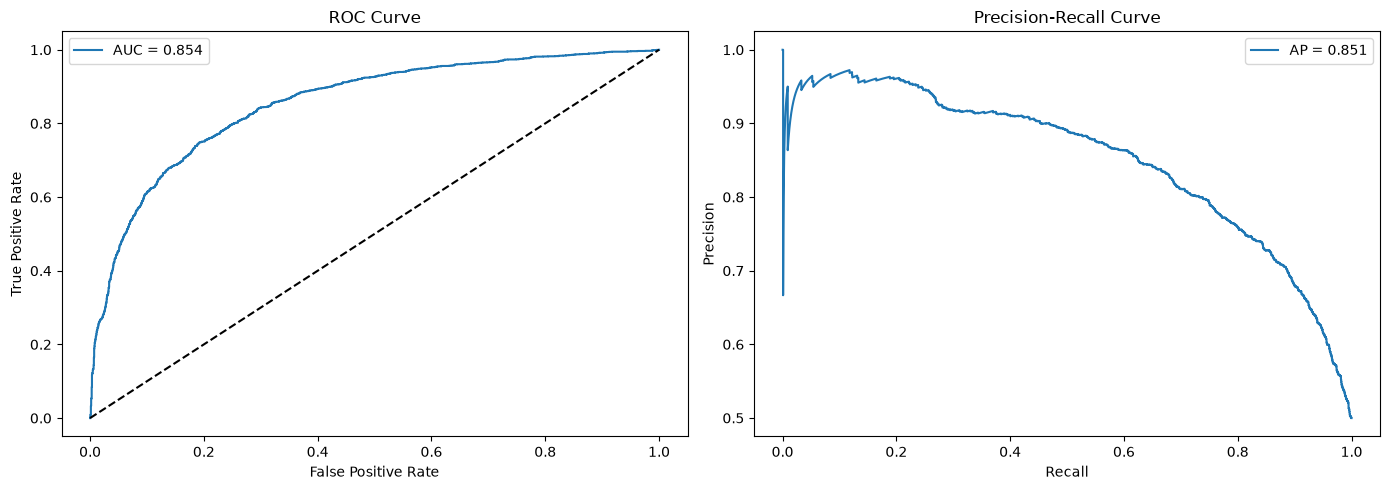

In [15]:
# Best parameters and score
print("Best Parameters:", LR_random_search.best_params_)
print("Best CV Average Precision:", LR_random_search.best_score_)

LR_best_pipeline = LR_random_search.best_estimator_
y_pred = LR_best_pipeline.predict(X_test)
y_prob = LR_best_pipeline.predict_proba(X_test)[:, 1]

print("Average Precision(Test):", average_precision_score(y_test, y_prob))
print("F1(Test):", f1_score(y_test, y_pred))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

ax[0].plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
ax[0].plot([0,1],[0,1],'k--')
ax[0].set_title('ROC Curve')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].legend()

# Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, y_prob)
ap = average_precision_score(y_test, y_prob)

ax[1].plot(recall, precision, label=f'AP = {ap:.3f}')
ax[1].set_title('Precision-Recall Curve')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()

plt.tight_layout()
plt.show()

**Result:** the best settings are an L1 penalty with `C=100`. CV PR-AUC is 0.844, test PR-AUC is 0.851, test ROC-AUC is 0.854 and test F1 is 0.765.

# XGBoost

In [16]:
# XGBoost
xgboost_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(subsample=0.8, colsample_bytree=0.8, max_delta_step=1,
                                 eval_metric="aucpr", random_state=RANDOM_SEED, n_jobs=1)),
])

xgboost_grid = {
    "classifier__max_depth": [2, 3, 4],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__n_estimators": [100, 300, 500]
}

XGB_random_search = RandomizedSearchCV(
    xgboost_pipeline,
    xgboost_grid,
    n_iter=12,                         # Number of random combinations
    scoring="average_precision",       # Metric for evaluation
    cv=10,                             # 10-fold cross-validation
    random_state=RANDOM_SEED,
    n_jobs=-1                          # Use all CPU cores
)

# Fit random search
XGB_random_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__learning_rate': [0.01, 0.05, ...], 'classifier__max_depth': [2, 3, ...], 'classifier__n_estimators': [100, 300, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` ins

Best Parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1}
Best CV Average Precision: 0.8578544334702712
Average Precision(Test): 0.8591276355119499
F1(Test): 0.7789066279632317


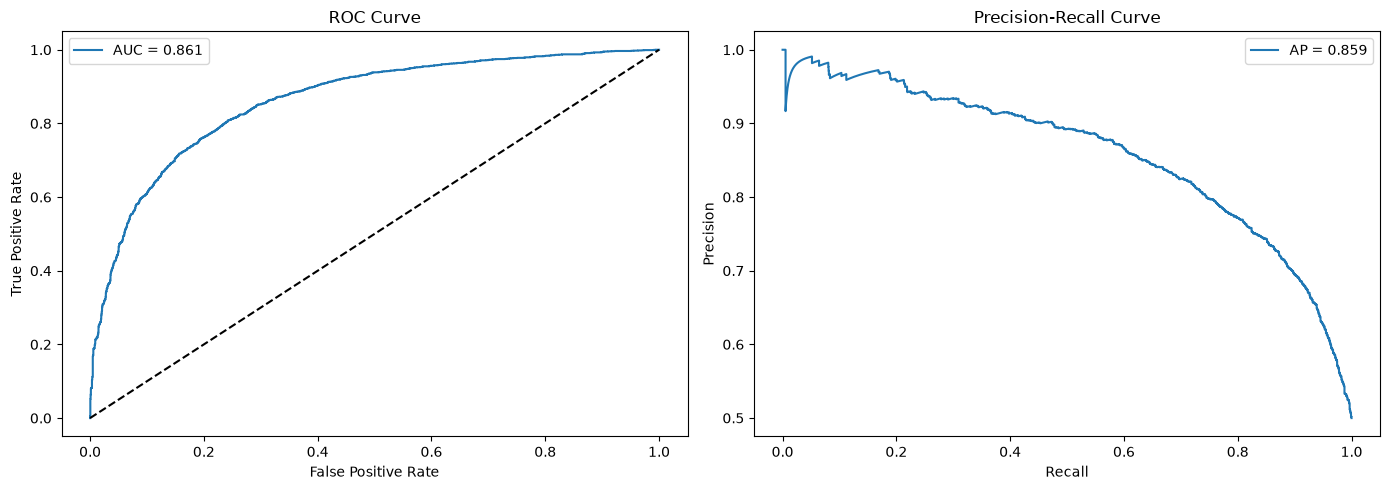

In [17]:
# Best parameters and score
print("Best Parameters:", XGB_random_search.best_params_)
print("Best CV Average Precision:", XGB_random_search.best_score_)

XGB_best_pipeline = XGB_random_search.best_estimator_
XGB_y_pred = XGB_best_pipeline.predict(X_test)
XGB_y_prob = XGB_best_pipeline.predict_proba(X_test)[:, 1]

print("Average Precision(Test):", average_precision_score(y_test, XGB_y_prob))
print("F1(Test):", f1_score(y_test, XGB_y_pred))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fpr, tpr, _ = roc_curve(y_test, XGB_y_prob)
roc_auc = roc_auc_score(y_test, XGB_y_prob)

ax[0].plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
ax[0].plot([0,1],[0,1],'k--')
ax[0].set_title('ROC Curve')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].legend()

# Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, XGB_y_prob)
ap = average_precision_score(y_test, XGB_y_prob)

ax[1].plot(recall, precision, label=f'AP = {ap:.3f}')
ax[1].set_title('Precision-Recall Curve')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()

plt.tight_layout()
plt.show()

**Result:** the best settings are `n_estimators=100`, `max_depth=3` and `learning_rate=0.1`. CV PR-AUC is 0.858, test PR-AUC is 0.859, test ROC-AUC is 0.861 (Gini 0.722) and test F1 is 0.779.

## Recall and confusion matrix

These show how the model performs at the default 0.5 threshold.

Recall: 0.7707


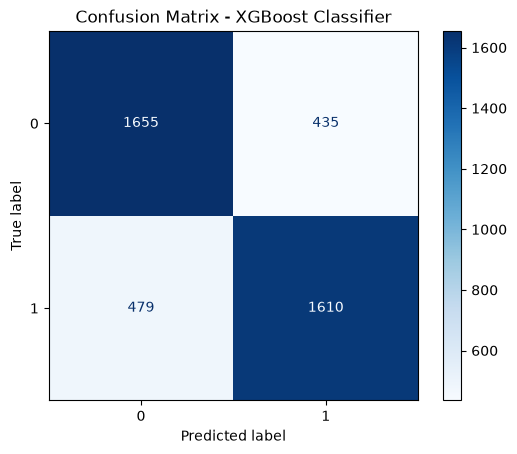


Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.79      0.78      2090
           1       0.79      0.77      0.78      2089

    accuracy                           0.78      4179
   macro avg       0.78      0.78      0.78      4179
weighted avg       0.78      0.78      0.78      4179



In [18]:
recall = recall_score(y_test, XGB_y_pred)
print(f"Recall: {recall:.4f}")

cm = confusion_matrix(y_test, XGB_y_pred, labels=XGB_best_pipeline.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=XGB_best_pipeline.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - XGBoost Classifier")
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, XGB_y_pred))

**Result:** recall is 0.771, so the model catches 1,610 of 2,089 delinquent borrowers and misses 479. It also wrongly flags 435 of 2,090 non-delinquent borrowers. Moving the threshold trades one error for the other, so a real threshold should reflect the cost of each error.

## KS

KS is the largest gap between the cumulative score distributions of delinquent and non-delinquent borrowers. It ranges from 0 to 1, and a higher value means better separation.

KS: 0.566 at score 0.453


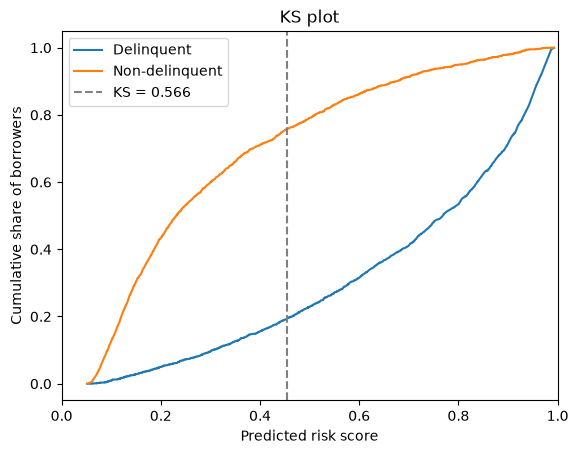

In [19]:
XGB_y_prob = XGB_best_pipeline.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, XGB_y_prob)
ks_index = np.argmax(tpr - fpr)
ks = tpr[ks_index] - fpr[ks_index]
print(f"KS: {ks:.3f} at score {thresholds[ks_index]:.3f}")

plt.plot(thresholds[1:], 1 - tpr[1:], label="Delinquent")
plt.plot(thresholds[1:], 1 - fpr[1:], label="Non-delinquent")
plt.axvline(thresholds[ks_index], color="grey", linestyle="--", label=f"KS = {ks:.3f}")
plt.gca().set(title="KS plot", xlabel="Predicted risk score",
              ylabel="Cumulative share of borrowers", xlim=(0, 1))
plt.legend()
plt.show()

## SHAP

SHAP shows how much each feature pushed a score up or down, in log-odds. The first chart shows the overall drivers, and the second explains one borrower's score.

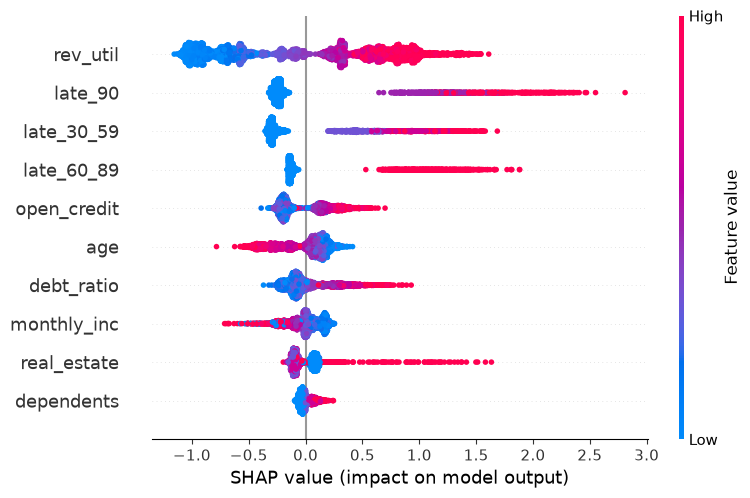

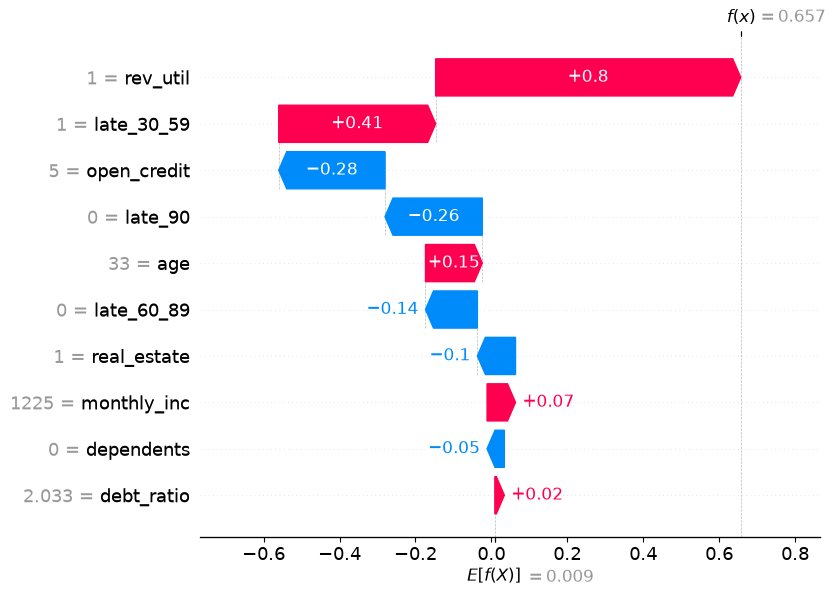

In [20]:
xgb_model = XGB_best_pipeline.named_steps["classifier"]
X_test_transformed = XGB_best_pipeline.named_steps["preprocessor"].transform(X_test)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_transformed)
shap_values.feature_names = X_test.columns.tolist()
shap_values.data = X_test.to_numpy()      # show original values, not log-scaled ones

shap.plots.beeswarm(shap_values, max_display=10)    # overall drivers
shap.plots.waterfall(shap_values[0])                # one borrower's score

## SHAP findings

- **Revolving utilization:** `rev_util` has the largest overall impact. High utilization raises risk and low utilization lowers it.
- **Payment history:** any late payment raises risk sharply, and `late_90` has the largest individual effects. Having no late payments lowers risk only slightly.
- **Income, debt and age:** higher income and older age lower predicted risk, while a higher debt ratio raises it.
- **Agreement with EDA:** `rev_util` also has the strongest Spearman correlation with the target, so the two views agree.
- **Example borrower:** this borrower scores 0.657 log-odds, or about 66% against a base of 50%. Maxed-out utilization (+0.80) and one 30–59 day late payment (+0.41) raise the score, while five open credit lines (−0.28) and no 90-day late payments (−0.26) lower it.
- **Caution:** SHAP explains how the model behaves, not what causes delinquency.

## Save the model

The full pipeline is saved with joblib, so the preprocessing and the model stay together.

In [21]:
model_metadata = {
    "model": XGB_best_pipeline,
    "best_params": XGB_random_search.best_params_,
    "best_cv_score": XGB_random_search.best_score_,
    "metric": "average_precision",
    "scikit_learn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__
}
joblib.dump(model_metadata, "best_credit_risk_XGBoost_model.pkl")

['best_credit_risk_XGBoost_model.pkl']

## Findings

| Metric | Logistic Regression | XGBoost |
|---|---|---|
| PR-AUC, 10-fold CV | 0.844 | **0.858** |
| PR-AUC, test | 0.851 | **0.859** |
| ROC-AUC, test | 0.854 | **0.861** |
| Gini, test (2 × AUC − 1) | 0.708 | **0.722** |
| F1 at 0.5 threshold, test | 0.765 | **0.779** |

- XGBoost leads on both cross-validation and the test set, so it is saved as the final model.
- The gap is small, which suggests a linear model already captures much of the signal.
- Flagging the placeholder codes as a separate feature was also tested on Logistic Regression. CV PR-AUC stayed at 0.844, so the simpler pipeline was kept.

# 6. Inference Test

Reload the saved pipeline and score three example borrowers: one with no risk signs and two with late payments.

In [22]:
import pandas as pd
import numpy as np
import xgboost
import joblib
from pathlib import Path
from xgboost import XGBClassifier

In [23]:
model_metadata = joblib.load("best_credit_risk_XGBoost_model.pkl")
model = model_metadata["model"]

print(model_metadata["best_params"])
print(model_metadata["best_cv_score"])

{'classifier__n_estimators': 100, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1}
0.8578544334702712


In [24]:
sample_df = pd.DataFrame([
    # No Risk
    {
        "rev_util": 0.15,
        "age": 45,
        "late_30_59": 0,
        "debt_ratio": 0.25,
        "monthly_inc": 12000,
        "open_credit": 8,
        "late_90": 0,
        "real_estate": 2,
        "late_60_89": 0,
        "dependents": 2
    },

    # Got Risk
    {
        "rev_util": 0.75,
        "age": 35,
        "late_30_59": 1,
        "debt_ratio": 0.80,
        "monthly_inc": 6000,
        "open_credit": 10,
        "late_90": 0,
        "real_estate": 1,
        "late_60_89": 1,
        "dependents": 3
    },

    # Got Risk
    {
        "rev_util": 1.20,
        "age": 26,
        "late_30_59": 4,
        "debt_ratio": 2.10,
        "monthly_inc": 2500,
        "open_credit": 18,
        "late_90": 3,
        "real_estate": 0,
        "late_60_89": 2,
        "dependents": 5
    }
])

In [25]:
new_borrower_prediction = model.predict(sample_df)
new_borrower_probability = model.predict_proba(sample_df)[:, 1]

print(new_borrower_prediction)
print(new_borrower_probability)

[0 1 1]
[0.12426629 0.8972823  0.9898325 ]


**Result:** the model predicts class 0 for the first borrower (score 0.124) and class 1 for the other two (scores 0.897 and 0.990). These scores reflect the 50/50 training sample, so they should not be read as real-world probabilities of default.

# 7. Conclusion

XGBoost is the final model, with a test PR-AUC of 0.859, ROC-AUC of 0.861, KS of 0.566 and recall of 0.771. Revolving utilization and late-payment history are its main drivers.

**Limitations and next steps:**

- **Balanced sample:** real portfolios have far fewer delinquent borrowers, and this dataset does not give the real rate. Precision would be lower in practice, and scores would need recalibrating to a real portfolio before being read as probabilities of default.
- **Decision threshold:** results use the default 0.5 cutoff. The next step is to set the threshold from the cost of missed defaults versus rejected good borrowers.
- **Placeholder values:** the meaning of the 96 and 98 codes is undocumented and should be confirmed with the data owner.
- **Fair lending:** `age` is restricted in credit decisions in many jurisdictions, so it would need review before any real use.